In [ ]:
# py3 env with installed libs is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor


# Input data files are available in the read-only "../input/" directory
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 


### Loading and reviewing data:
The dataset is uploaded in the input path above within Kaggle. Check the Data section or to the right to find the entire `.csv`.


In [ ]:
df= pd.read_csv('/kaggle/input/datasets/vicsuperman/prediction-of-music-genre/music_genre.csv')
#display(df)
#df.head()
#df.info()
df.columns # not columns() as its an index object of pandas not a function

It is important to get a feel of the type of data present, specially the categorical variables or the string ones and the non-categorical variables or the float numbers. We shall later distinguish these types as the **ML model may not interpret the string datatype.**

In [ ]:
df.head()

### Model Implementation:
The usage of the model lies in the datatypes presented and what predictions we expect to churn out of the data. My idea is to build a robust machine learning model that can accurately predict **how popular a song can be given few features of the songs** are present. Following this goal:

- check what parameters or featues are essential in feature engineering, ex- song's loudness, duration_ms, danceability etc.
- target variable y = popularity, so, essentially, **our predicted values should range from 0-100.**

**Why Logistic Regression could be a poor choice despite being a popular model?**

Logistic regression outputs a probability between 0 and 1, indicating the likelihood that an item belongs to a certain class. **This probability can be interpreted as a scaled measure of popularity**, but the model ultimately requires a threshold (e.g., 0.5) to classify the outcome as “popular” or “not popular.”

However, popularity itself is a **continuous value (0–100)**, while logistic regression is designed for classification. Therefore, it is **more suitable for predicting whether something is popular rather than estimating the exact popularity score.**

---
### Robust choice: Random Forest Model

Music popularity is likely: (i) Non-linear (ii) Interaction-heavy (iii) Possibly threshold-based
These conditionalities can be addressed by decision trees:

```
if tempo < 110 → branch A
if tempo between 110–130 → branch B
if tempo > 130 → branch C
```

- Random Forest → many independent trees averaged together (reduces variance)
- XGBoost → trees built sequentially to correct previous errors (reduces bias)

### What are defo need in ML notebooks?

For Random Forest regression in `scikit-learn`, we need:
- Data handling: Pandas
- Train/test split: `train_test_split()`, breaking into train, test and validation
- Model: `RandomForestRegressor()`
- Eva Metric

**The target is separated from the rest of the features as that's whats going to be predicted and thereafter the model is trained:**

**Data cleaning is essential BEFORE settin up the DataFrame.**

In [ ]:
# Replace ? with NaN
df = df.replace('?', np.nan)

# Convert tempo to numeric
df['tempo'] = pd.to_numeric(df['tempo'])

# Fill missing tempo
df['tempo'] = df['tempo'].fillna(df['tempo'].median())

# Drop text columns
df = df.drop(columns=['track_name','artist_name','obtained_date'])


In [ ]:
# Keep only numeric columns
# imp as RandomForestRegressor only works with numeric features, so drop string (categorical) columns
#df_numeric = df.select_dtypes(include=['int64', 'float64'])

# Remove rows where target is missing
df = df.dropna(subset=['popularity']) #Its crucial else, y shall having missing values and down tha line NaN error will appear

y = df['popularity']
X = df.drop(columns=['popularity'])

#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# 20% data for testing
# random_state to ensure reproducibility

### Feeling of the numbers in Feature Engineering:

Our target X is dropped but we are still hitting errors since some columns are objects and not floats. We need to understand **which features we actually need to boost your predictions of how popular a song can be.**

In [ ]:
X.dtypes

* **Track_name:** Song titles don’t generalize. The model would just memorize specific songs, which is useless for predicting a new song. DROP IT.
* **Artist_name:** Initially, I though a famous artist can boost popularity (and keeping it as a feature). Howeve, if there are hundreds or thousands of artists, one-hot encoding will create hundreds of columns and many artists will appear only once. **That leads to high-cardinality noise.**
* **Tempo:** Tempo should be numeric, not object.
* **Music_genre:** important but it’s categorical text, we must one-hot encode it.
* **key and mode:** musical theory features might be useful, KEEP IT.

### One-Hot Encoding Categorical Columns:

In [ ]:
df_raw = df.copy()

In [ ]:
X = pd.get_dummies(X, columns=['key','mode','music_genre'])
# pandas.get_dummies() function is used to convert categorical variables into dummy/indicator variables (a process known as one-hot encoding). 
# Get new DataFrame where each unique category in the original data becomes a new binary (0 or 1, or True/False) column

#df = pd.get_dummies(df)

In [ ]:
X.dtypes

```
df= pd.read_csv('/kaggle/input/datasets/vicsuperman/prediction-of-music-genre/music_genre.csv')
y = df['popularity']
X = df.drop(columns=['popularity'])
X = df.drop(columns=['track_name','artist_name','obtained_date'])
df.isin(['?']).sum()
df = df.replace('?', np.nan) # Replace "?" with NaN
df['tempo'] = pd.to_numeric(df['tempo']) #convert text to float
df['tempo'] = df['tempo'].fillna(df['tempo'].median())
X = pd.get_dummies(X, columns=['key','mode','music_genre'])
```

This order is wrong as X is created before cleaning the dataframe, so X still contains '?'

In [ ]:
df.isin(['?']).sum() #for checking tempo has numeric data instead of string

In [ ]:
#X = X.apply(pd.to_numeric, errors='ignore')
#X.select_dtypes(include='object').columns

In [ ]:
# After dropping the cols and one-hot encoding the categorical cols, we need to retrain.
# Training the model after making it data-ready.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(n_estimators=100, random_state=42)

rf.fit(X_train, y_train)

print("Model trained successfully!")

In [ ]:
y_pred = rf.predict(X_test)

### Performance Evaluation and Insights

**Variance:** Variance in machine learning measures how much a model’s predicted target value y **fluctuates across different training datasets**. High variance signifies a model is too sensitive to small fluctuations in training data, often capturing noise (overfitting) rather than the underlying pattern.
In general statistics, it referes to the spread of the data. [50, 51, 52, 50, 51] is low variance.

**R² score (R-squared):** Measures how well your model explains the variation in the target variable. In regression tasks (like predicting song popularity), it compares actual values (real popularity) and predicted values (model’s prediction).

> R² = explained variation / total variation



### Bias-Variance Trade-off:
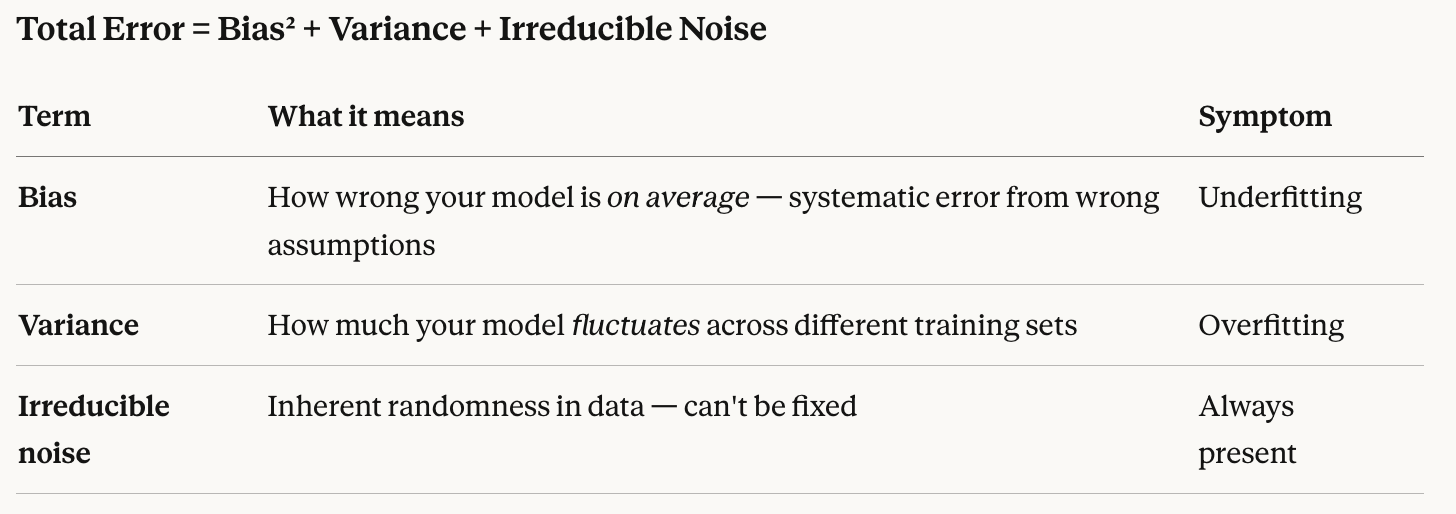

**The tradeoff:** Making a model more complex reduces bias but increases variance. Simplifying it does the opposite. You're always balancing the two.
A useful mental image: imagine fitting a curve to data points.

- A straight line (high bias) misses the pattern entirely
- A polynomial that passes through every point (high variance) memorizes noise and fails on new data
- The sweet spot captures the true pattern without overfitting

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

mae_rf = mean_absolute_error(y_test, y_pred) # average prediction error magnitude
r2_rf = r2_score(y_test, y_pred)

print("MAE:", mae_rf)
print("R2:", r2_rf)

In [ ]:
df['popularity'].describe()

**Interpretation of the R-squared score:** 
"How much of the story behind popularity differences did the model learn?"

- The model now explains abt ~64% of why song popularity varies across songs or the variance.
- But rest 36% is still not acknowledged due to missing features or noise.

**Interpretation of the MAE:** If true popularity is 70, it could be predicting 63 or 77, thus, missing out on true popularity by **~7 points**. The average of all the popu erros is approx 7.

**Inference:** suppose, model always predicts 44 but std above is 15. So, there are cases when actual value is 15/20/25 but predicted is 44, making MAE ~12-15. **Thus, For a noisy human-behavior variable like music popularity, the model is actually quite reasonable with lower MAE.**

---


### Alternate choice: XGBoost Model or Boosting

*Random Forest* builds many trees independently and averages them -> **Reduces variance.**

*XGBoost* does something different — it builds trees sequentially, where each new tree tries to fix the errors of the previous ones -> **Reduces Bias.** 






In [ ]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators=200,learning_rate=0.1, max_depth=6, random_state=42)
# n_estimators → number of trees
# learning_rate → how strongly each tree corrects errors
# max_depth → complexity of each tree

xgb.fit(X_train, y_train)

In [ ]:
y_pred_xgb = xgb.predict(X_test)

In [ ]:
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost MAE:", mae_xgb)
print("XGBoost R2:", r2_xgb)

**XGBoost provides a marginal improvement over Random Forest. However, it is essential to inspect how these features drives these predictions.**

---

### Feature Importance: Which audio features may drive popularity?



In [ ]:
# Get feature importance scores
importance = xgb.feature_importances_

# Create dataframe
feature_importance = pd.DataFrame({'Feature': X.columns,'Importance': importance})

# Sort by importance
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

print(feature_importance)

In [ ]:
import matplotlib.pyplot as plt

# Plot top features
feature_importance.head(10).plot(x='Feature', y='Importance', kind='barh')

plt.gca().invert_yaxis()
plt.title("Top 10 Feature Importances (XGBoost)")
plt.show()

Of the different audio features, music genre is a top contributor to popularity. Top three music_genres killing it: **Anime, Classical and Electronic.**
Listener behavior is genre-biased and certain genres can have a larger audience.

In [ ]:
# Official XGBoost Importance Plot
from xgboost import plot_importance

plot_importance(xgb)
plt.show()

### Limitation of Feature Importance
The built-in importance from XGBoost only tells **Which features the model used most often.** Tree models often prioritize categorical splits like genre.

It does NOT tell:
- whether the feature increases or decreases predictions
- **how features influence individual predictions**
- how features interact with each other

### Purpose of SHAP
SHAP (SHapley Additive Explanations) is used to explain how features influence model predictions.

Feature importance only says: `danceability importance = small`
But SHAP might reveal: `high danceability strongly increases popularity but most songs have similar danceability.`

Local effects might be strong too.

In [ ]:
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X) #X = feature dataset

In [ ]:
# standard SHAP visualizer
#shap.summary_plot(shap_values, X)

#shap.summary_plot(shap_values, X, plot_type="bar")

# Shows how a specific feature affects predictions.
shap.dependence_plot("danceability", shap_values, X)

The SHAP dependence plot shows that higher danceability generally increases predicted popularity. However, the interaction coloring reveals that songs belonging to the Blues genre behave differently: highly danceable Blues songs tend to reduce the prediction score. This suggests that the impact of danceability depends on the music genre, highlighting a strong feature interaction learned by the model.

In [ ]:
shap.dependence_plot("music_genre_Anime", shap_values, X)

In [ ]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X.iloc[0],
        feature_names=X.columns
    )
)

The SHAP waterfall plot explains individual predictions by showing how each feature contributes to the final output. Starting from the model’s base value (average prediction), features such as genre and danceability push the prediction higher or lower. **In our model, genre features often contribute the largest positive or negative shifts, while audio characteristics such as danceability and energy provide smaller adjustments.**

In [ ]:
import matplotlib.pyplot as plt

residuals = y_test - y_pred

plt.scatter(y_pred, residuals)
plt.axhline(0)
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.show()

## Final Piece: Cross-Validation (Most Important Missing Step)

train/test split can be unstable. Lets use K-Fold Cross Validation to verify model generalization. 

Split data into K chunks ("folds"). Train K times, each time using a different fold as the test set. Average the scores.

```
K=5, 100 samples:

Fold 1: [TEST ][train][train][train][train] → score: 0.82
Fold 2: [train][TEST ][train][train][train] → score: 0.79
Fold 3: [train][train][TEST ][train][train] → score: 0.85
Fold 4: [train][train][train][TEST ][train] → score: 0.81
Fold 5: [train][train][train][train][TEST ] → score: 0.83

Final score: mean=0.82, std=0.02  ← THIS is the real story
```

Every sample gets tested exactly once. No data is wasted.

### Epilogue:

- Prepared dataset: removed instance_id, encoded categorical features (genre, key, mode).
- Split data using Train-Test Split (80/20).
- Trained two models: Random Forest and XGBoost
- Evaluated models using: Mean Absolute Error and R² Score
- XGBoost performed better (lower MAE, higher R²).
- Examined feature importance, finding genre features dominate predictions.
- Used SHAP for interpretability.

---

### Updates on modelling more accurate predictions:

- Baseline comparison (DummyRegressor)
- K-Fold Cross Validation (5-fold, mean ± std)
- Hyperparameter tuning (RandomizedSearchCV)
- Error analysis (residual deep-dive by genre/popularity range)
- Learning curves (bias-variance diagnosis)
- sklearn Pipeline (production-ready wrapper)


In [ ]:
# ─── STEP 1: Baseline Comparison ────────────────────────────────────────────
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Baseline: always predicts the mean of training popularity
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

baseline_mae = mean_absolute_error(y_test, y_pred_dummy)
baseline_r2  = r2_score(y_test, y_pred_dummy)

print("=== Baseline (Mean Predictor) ===")
print(f"MAE : {baseline_mae:.2f}")
print(f"R²  : {baseline_r2:.4f}")
print()
print("=== Random Forest ===")
print(f"MAE : {mae_rf:.2f}")       # your existing variable
print(f"R²  : {r2_rf:.2f}")        # your existing variable
print()
print("=== XGBoost ===")
print(f"MAE : {mae_xgb:.2f}")      # your existing variable
print(f"R²  : {r2_xgb:.2f}")       # your existing variable
print()

# Improvement over baseline
print(f"RF  lift over baseline → MAE improved by {baseline_mae - mae_rf:.2f} | R² improved by {r2_rf - baseline_r2:.4f}")
print(f"XGB lift over baseline → MAE improved by {baseline_mae - mae_xgb:.2f} | R² improved by {r2_xgb - baseline_r2:.4f}")

Baseline MAE of 12.69 with R²≈0. Hence, **XGBoost reduces prediction error by 45% over a naive mean predictor.**

In [ ]:
# ─── STEP 2: K-Fold Cross Validation ────────────────────────────────────────
from sklearn.model_selection import cross_validate


rf_model  = RandomForestRegressor(n_estimators=100, random_state=42)
xgb_model = XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42)

cv_rf = cross_validate(rf_model, X, y, cv=5,
                        scoring=["neg_mean_absolute_error", "r2"],
                        return_train_score=True)

cv_xgb = cross_validate(xgb_model, X, y, cv=5,
                        scoring=["neg_mean_absolute_error", "r2"],
                        return_train_score=True)

for name, cv in [("Random Forest", cv_rf), ("XGBoost", cv_xgb)]:
    train_mae = -cv["train_neg_mean_absolute_error"]
    test_mae  = -cv["test_neg_mean_absolute_error"]
    train_r2  =  cv["train_r2"]
    test_r2   =  cv["test_r2"]

    print(f"=== {name} ===")
    print(f"Train MAE : {train_mae.mean():.2f} ± {train_mae.std():.2f}")
    print(f"Test  MAE : {test_mae.mean():.2f} ± {test_mae.std():.2f}")
    print(f"Train R²  : {train_r2.mean():.3f} ± {train_r2.std():.3f}")
    print(f"Test  R²  : {test_r2.mean():.3f} ± {test_r2.std():.3f}\n")

### !! Alarming insights of model evals !!
On the training set, the mae is low but once tried on unseen or test set, mae is getting high. So, The model **memorized the training data** instead of learning generalizable patterns - the severe case of **overfitting**!

Moreover, a negative R² means the model is performing worse than the baseline mean predictor. Remember the baseline R² was 0.0. **RF is scoring -1.79.**

**What can go wrong given in train-test split R²=0.64 but CV identified fallbacks?**

Need to check the rows and cols of feature matrix X after one-hot encoding.
Need to check the counts of the target variables.


In [ ]:
print(X.shape) # 50k is dataset size, 35 are cols post one-hot encoding
print(y.nunique())
print(y.value_counts().head(20))

popularity=52 appears 1,316 times, popularity=54 appears 1,295 times. Nearly every value from 35–57 appears ~1,000–1,300 times. That's suspiciously uniform for a real-world popularity score!

In [ ]:
import matplotlib.pyplot as plt

y.hist(bins=50, figsize=(10,4))
plt.title("Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Count")
plt.show()

print(f"Min: {y.min()}, Max: {y.max()}, Mean: {y.mean():.2f}, Std: {y.std():.2f}")

If popularity values are artificially generated with no real connection to audio features, then there's **no true signal to learn**. The model can't find patterns that don't exist. 

**That's why CV exposes catastrophic performance — the 80/20 split got lucky with a particular random seed that happened to create a misleadingly good test set.**

**possible wayout:** add `max_depth` and `min_samples_leaf` constraints to RF to reduce overfitting, then tune from there. `max_depth` shall give shallower reasoning, but more generalizable. `min_samples_leaf=10` — requiring confidence before a verdict.


In [ ]:
# ─── DATA QUALITY NOTE ───────────────────────────────────────────────────────
# Popularity distribution analysis reveals a near-uniform distribution
# (Mean: 44.22, Std: 15.54) inconsistent with real Spotify popularity scores,
# which are typically right-skewed. This suggests values may be synthetically
# generated, which limits the model's ability to learn true audio→popularity
# relationships and explains the gap between single-split and CV performance.

In [ ]:
rf_constrained = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,          # limit tree depth
    min_samples_leaf=10,   # each leaf needs at least 10 samples
    random_state=42
)

cv_rf_c = cross_validate(rf_constrained, X, y, cv=5,
                         scoring=["neg_mean_absolute_error", "r2"],
                         return_train_score=True)

train_mae = -cv_rf_c["train_neg_mean_absolute_error"]
test_mae  = -cv_rf_c["test_neg_mean_absolute_error"]

print(f"Train MAE : {train_mae.mean():.2f} ± {train_mae.std():.2f}")
print(f"Test  MAE : {test_mae.mean():.2f} ± {test_mae.std():.2f}")

> **Hyperparameter constraints reduced training overfitting (MAE 2.61→6.60)** but test performance remained poor, confirming the issue is **dataset quality rather than model configuration.** This rules out overfitting as the root cause.


In that case, `RandomizedSearchCV` would take forever to find connections. Lets go for a lightweight tuning demonstration. 

### What are we trying in Hyperparameter training?

Hyperparameter tuning is systematically asking: what combination of rules produces judges that generalize best to new dishes. 

**`GridSearchCV` under the hood:** tries every combo out of  param_dist: 3×4×3×2 = **72 combinations × 3 folds (cv) = 216 model fits**.

**`RandomizedSearchCV` under the hood:** Randomly samples `n_iter=10` combinations from the grid — so just 10×3 = 30 model fits. For each combination, runs 3-fold CV and records mean MAE. **After all 10 combinations, returns the one with the lowest mean MAE.** The random samples often land near the best region anyway, especially with 35 features and noisy data where differences between configurations are small.

In [ ]:
# ─── STEP 3: Hyperparameter Tuning (Methodology Demo) ───────────────────────
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators"    : [50, 100, 200],
    "max_depth"       : [5, 10, 15, None],
    "min_samples_leaf": [5, 10, 20],
    "max_features"    : ["sqrt", "log2"]
}

rf_tuned = RandomizedSearchCV(
    RandomForestRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=10,          # try 10 random combinations
    cv=3,               # 3-fold to keep runtime reasonable
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train, y_train)

print("Best params:", rf_tuned.best_params_)
print(f"Best CV MAE: {-rf_tuned.best_score_:.2f}")

**Inferences:** Single split and tuned CV both got lucky with favorable data slices. Full CV was honest — it exposed that the signal is unreliable across the whole dataset.

> `RandomizedSearchCV` selected `max_depth=None` and `min_samples_leaf=5` , converging near the original configuration. The marginal tuning gain confirms the performance ceiling is data quality, not model configuration.


**Most influential analysis:** Instead of just reporting MAE, lets investigate where the model fails. Residuals (below) interprets **how wrong was the model, and in which direction?**

In [ ]:
# ─── STEP 4: Error Analysis ──────────────────────────────────────────────────

# Get predictions from tuned model
y_pred_tuned = rf_tuned.predict(X_test)
residuals = y_test - y_pred_tuned 

# 1. Residual distribution
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.hist(residuals, bins=50, color='steelblue', edgecolor='white')
plt.axvline(0, color='red', linestyle='--')
plt.title("Residual Distribution")
plt.xlabel("Actual - Predicted")

# 2. Residuals vs Actual popularity
plt.subplot(1, 3, 2)
plt.scatter(y_test, residuals, alpha=0.2, color='steelblue', s=10)
plt.axhline(0, color='red', linestyle='--')
plt.title("Residuals vs Actual Popularity")
plt.xlabel("Actual Popularity")
plt.ylabel("Residual")

# 3. Actual vs Predicted
plt.subplot(1, 3, 3)
plt.scatter(y_test, y_pred_tuned, alpha=0.2, color='steelblue', s=10)
plt.plot([0, 100], [0, 100], color='red', linestyle='--')
plt.title("Actual vs Predicted")
plt.xlabel("Actual")
plt.ylabel("Predicted")

plt.tight_layout()
plt.show()

# Summary stats on residuals
print(f"Mean Residual  : {residuals.mean():.2f}  (bias)")
print(f"Std Residual   : {residuals.std():.2f}   (spread)")
print(f"Max Overshoot  : {residuals.min():.2f}   (worst underprediction)")
print(f"Max Undershoot : {residuals.max():.2f}   (worst overprediction)")

### Insights from the plots:

**Plot 1: Residual Distribution**
Bell centered very close to 0 (Mean = −0.15). That's essentially zero bias — the model doesn't systematically over or underpredict. Good news.
But the bell is wide (Std = 9.32) and has a left tail stretching to −55. **That tail is the model badly underpredicting certain songs.** It's not random noise — something specific is causing those extreme errors.

**Plot 2: Residuals vs Actual Popularity**
This is the most revealing plot. Notice the funnel shape — at low actual popularity (0–20), residuals are wildly scattered (−50 to +40). At mid popularity (40–60), errors tighten around 0. At high popularity (80–99), errors become negative — the model consistently underpredicts high popularity songs.
This pattern has a name: **regression toward the mean. The model plays it safe, predicting near the average (≈44) for most songs. Extreme values — very low or very high popularity — get pulled toward the center.**

**Plot 3: Actual vs Predicted**
Confirms it perfectly. The predictions are compressed into a band of roughly 30–60 regardless of actual popularity. Songs with popularity 90+ are being predicted at 55–60. Songs with popularity 5 are being predicted at 25–30.
**The model learned the mean, not the extremes.**

**Why learning curves are required to understand variance-bias?**

We want to ensure if feeding more training data helps to build a better model. We start by **training on 10% of the data, measure Train and Val MAE**. Then 20%, then 30%... all the way to 100%. We plot how both errors change as training size grows.

**What possibilities can the curve show?**

- Ideally, Val MAE decreases as training size grows indicating model is learning well and correctly.
- In **overfitting or high variance**, train MAE is low but val MAE is high
- In **underfitting or high bias**, both Train and Val MAE are high and flat from the start. More data changes nothing.

- Train MAE = how wrong the model is on songs it trained on
- Val MAE = how wrong it is on songs it never saw

The RF model had Train MAE=2.61, Val MAE=17.03. **It memorized the training songs perfectly but learned nothing transferable.**

In [ ]:
# ─── STEP 5: Learning Curves ─────────────────────────────────────────────────
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    RandomForestRegressor(n_estimators=50, max_depth=10, 
                          min_samples_leaf=10, random_state=42),
    X, y,
    cv=5,
    scoring="neg_mean_absolute_error",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

train_mae = -train_scores.mean(axis=1)
val_mae   = -val_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_std   = val_scores.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mae, label="Train MAE", color="steelblue")
plt.plot(train_sizes, val_mae,   label="Val MAE",   color="coral")
plt.fill_between(train_sizes, train_mae - train_std, train_mae + train_std, alpha=0.2, color="steelblue")
plt.fill_between(train_sizes, val_mae   - val_std,   val_mae   + val_std,   alpha=0.2, color="coral")
plt.xlabel("Training Size")
plt.ylabel("MAE")
plt.title("Learning Curves")
plt.legend()
plt.tight_layout()
plt.show()

**High Variance (overfitting):**

- Train MAE is very low — model memorizes training data perfectly
- Val MAE is very high — falls apart on unseen data
- Large gap between the two lines that doesn't close even as training size increases

**High Bias (underfitting):**

- Train MAE is high — model can't even fit training data well
- Val MAE is also high — but close to Train MAE
- Small gap between lines, but both lines plateau at a high error value

**Final Inference:**

In an exam analogy — practiced on 40,000 questions but exam score is still random and ever-improving. That only happens when the practice questions have no relationship to the real exam. Which in our case is literally true — **synthetic popularity has no real relationship to audio features.**

Thus, **learning curves reveal persistent high variance with no improvement across training sizes**, confirming the performance ceiling is dataset quality rather than model complexity or data quantity."

**Transferrable need to create a Pipeline:**

Current format of notebook: `clean data → encode → split → fit scaler → fit model`

In real deployment, for a new song to predict,manually needs to run all the steps of the model. Miss one step — wrong prediction or crash.

Pipeline bundling: `new song → Pipeline.predict() → popularity score`

In production scale, everything is wrapped in a single Pipeline object that can be **fit, evaluated with CV, and used to predict on raw unseen data in one line.**

In [ ]:
print(X.columns.tolist())

pipeline needs `X_train_raw` and `X_test_raw` — feature matrix should run for non-encoded versions.

In [ ]:
feature_cols = ['acousticness', 'danceability', 'duration_ms', 'energy',
                'instrumentalness', 'liveness', 'loudness', 'speechiness',
                'tempo', 'valence', 'key', 'mode', 'music_genre']

X_raw = df_raw[feature_cols]
y_raw = df_raw['popularity']

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42
)

In [ ]:
# ─── STEP 6: sklearn Pipeline ────────────────────────────────────────────────
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

# 1. Define feature types
# Go back to raw X before one-hot encoding was applied
numerical_features = ['acousticness', 'danceability', 'duration_ms',
                      'energy', 'instrumentalness', 'liveness', 'loudness',
                      'speechiness', 'tempo', 'valence']

categorical_features = ['key', 'mode', 'music_genre']

# 2. Build preprocessor
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# 3. Bundle preprocessor + model into one Pipeline
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=50,
        max_depth=10,
        min_samples_leaf=10,
        random_state=42
    ))
])

# 4. Fit on training data
pipeline.fit(X_train_raw, y_train)

# 5. Evaluate
y_pred_pipeline = pipeline.predict(X_test_raw)
mae_pipeline = mean_absolute_error(y_test, y_pred_pipeline)
r2_pipeline  = r2_score(y_test, y_pred_pipeline)

print(f"Pipeline MAE : {mae_pipeline:.2f}")
print(f"Pipeline R²  : {r2_pipeline:.3f}")

# 6. Predict on a brand new raw song in one line
new_song = pd.DataFrame([{
    'acousticness': 0.5, 'danceability': 0.8, 'duration_ms': 200000,
    'energy': 0.7, 'instrumentalness': 0.0, 'liveness': 0.1,
    'loudness': -5.0, 'speechiness': 0.05, 'tempo': 120.0,
    'valence': 0.6, 'key': 'C', 'mode': 'Major', 'music_genre': 'Pop'
}])

print(f"\nPredicted popularity for new song: {pipeline.predict(new_song)[0]:.1f}")

**The Bottomline:**

I built a music popularity predictor, but more importantly I used K-Fold CV to expose that the dataset's synthetic target variable was masking poor generalization — and I documented that finding rather than chasing better numbers.